In [1]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

In [2]:
df_labelrobot = pd.read_csv(r"D:\Project\DetectRobot\Data\RobotUser_20210714.csv")

In [3]:
df_labelrobot.head()

,CustID,RobotDate
0,8768,2020-12-04 05:28:00
1,9633,2020-12-06 07:39:00
2,21645,2020-12-04 05:28:00
3,24256,2019-09-18 11:55:00
4,31111,2020-12-04 05:28:00


In [4]:
df_labelrobot['label'] = 1

In [5]:
df_labelrobot.head()

,CustID,RobotDate,label
0,8768,2020-12-04 05:28:00,1
1,9633,2020-12-06 07:39:00,1
2,21645,2020-12-04 05:28:00,1
3,24256,2019-09-18 11:55:00,1
4,31111,2020-12-04 05:28:00,1


In [184]:
df_data = pd.read_csv(r"D:\Project\DetectRobot\Data\data_month6_eachday\data_106.csv")

C:\Users\darius.nguyen\AppData\Roaming\Python\Python37\site-packages\IPython\core\interactiveshell.py:3147: DtypeWarning: Columns (33) have mixed types.Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


In [188]:
df_data.head()

,Unnamed: 0,transid,custid,username2,transdate,hdp1,hdp2,odds,stake,status,...,currency,ip,srecommend,balance,sporttype,homeid,awayid,leagueid,category,file_name
0,0,112035496526,45703075,Cqefj@$2201551419,2021-05-30 02:35:57.857,0.0,5.5,0.94,25.0,running,...,13,124.64.18.190,32951615,615.3734,2,1997,1988,56054,NaN,bettrans_06_01_2021_00_28_15.csv
1,1,112036793359,50596826,365ssrpvn$RM888oNyy1169,2021-05-30 06:07:25.063,0.0,5.5,0.94,100.0,running,...,13,39.144.49.44,20121325,174.4900,2,1997,1988,56054,NaN,bettrans_06_01_2021_00_28_15.csv
2,2,112037269182,46831358,UUHryky$365nrH1oswMRPVEG998,2021-05-30 07:26:54.590,0.0,5.5,0.94,270.0,running,...,13,113.5.4.68,44914401,7000.1559,2,1997,1988,56054,NaN,bettrans_06_01_2021_00_28_15.csv
3,3,112039306447,46261851,Sclwj@lkq$]`d016pi_2vw2930584,2021-05-30 12:25:02.217,223.5,0.0,0.93,500.0,running,...,13,58.62.181.127,36130220,1000.5700,2,1997,1988,56054,NaN,bettrans_06_01_2021_00_28_15.csv
4,4,112039477826,45598888,NCUW$H^\h_0eNP7172030,2021-05-30 12:54:54.693,223.5,0.0,0.93,144.0,running,...,13,112.48.50.116,31607887,144.7285,2,1997,1988,56054,NaN,bettrans_06_01_2021_00_28_15.csv


In [187]:
df_data.sporttype.unique()

array([ 2,  8, 43,  6,  1,  5,  4, 56, 24], dtype=int64)

In [190]:
df_data['label'] = df_data.custid.map(df_labelrobot.set_index('CustID')['label'])

In [191]:
df_data['label'].fillna(0, inplace = True)

In [192]:
df_fulldata = df_data[['custid','username2','transdate','label']]

In [193]:
df_fulldata.head()

,custid,username2,transdate,label
0,45703075,Cqefj@$2201551419,2021-05-30 02:35:57.857,0.0
1,50596826,365ssrpvn$RM888oNyy1169,2021-05-30 06:07:25.063,0.0
2,46831358,UUHryky$365nrH1oswMRPVEG998,2021-05-30 07:26:54.590,0.0
3,46261851,Sclwj@lkq$]`d016pi_2vw2930584,2021-05-30 12:25:02.217,0.0
4,45598888,NCUW$H^\h_0eNP7172030,2021-05-30 12:54:54.693,0.0


In [194]:
df_fulldata['date'] = pd.to_datetime(df_fulldata['transdate']).dt.date

ipykernel_launcher:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [195]:
df_fulldata.head()

,custid,username2,transdate,label,date
0,45703075,Cqefj@$2201551419,2021-05-30 02:35:57.857,0.0,2021-05-30
1,50596826,365ssrpvn$RM888oNyy1169,2021-05-30 06:07:25.063,0.0,2021-05-30
2,46831358,UUHryky$365nrH1oswMRPVEG998,2021-05-30 07:26:54.590,0.0,2021-05-30
3,46261851,Sclwj@lkq$]`d016pi_2vw2930584,2021-05-30 12:25:02.217,0.0,2021-05-30
4,45598888,NCUW$H^\h_0eNP7172030,2021-05-30 12:54:54.693,0.0,2021-05-30


In [196]:
df_groupbydate = df_fulldata.groupby(['custid','date'])['transdate'].apply(list).to_frame()

In [197]:
df_groupbydate['Length']= df_groupbydate['transdate'].str.len()

In [198]:
df_groupbydate = df_groupbydate[df_groupbydate['Length'] > 5]

In [199]:
df_groupbydate.head()

,,transdate,Length
custid,date,,
12063,2021-06-01,"[2021-06-01 07:29:59.027, 2021-06-01 06:46:21....",12
44424,2021-06-01,"[2021-06-01 10:01:19.667, 2021-06-01 13:48:09....",7
87196,2021-06-01,"[2021-06-01 18:59:53.427, 2021-06-01 19:00:28....",8
89670,2021-06-01,"[2021-06-01 05:51:34.500, 2021-06-01 05:51:39....",77
140234,2021-06-01,"[2021-06-01 06:45:11.390, 2021-06-01 06:42:55....",70


In [200]:
from datetime import datetime
def calculate_difftime(list_data):
    list_data = sorted(list_data)
    #print(list_data)
    result = [((datetime.strptime(y, '%Y-%m-%d %H:%M:%S.%f') - datetime.strptime(x, '%Y-%m-%d %H:%M:%S.%f')).seconds)/60 for x,y in zip(list_data,list_data[1:])]
    #result = [((y-x).seconds)/60 for x,y in zip(list_data,list_data[1:])]
    return result

In [201]:
df_groupbydate['diff_time'] = df_groupbydate['transdate'].apply(calculate_difftime)

In [202]:
df_groupbydate.head()

,,transdate,Length,diff_time
custid,date,,,
12063,2021-06-01,"[2021-06-01 07:29:59.027, 2021-06-01 06:46:21....",12,"[16.066666666666666, 27.55, 8.5, 3.56666666666..."
44424,2021-06-01,"[2021-06-01 10:01:19.667, 2021-06-01 13:48:09....",7,"[170.25, 0.38333333333333336, 0.73333333333333..."
87196,2021-06-01,"[2021-06-01 18:59:53.427, 2021-06-01 19:00:28....",8,"[0.3333333333333333, 0.8166666666666667, 0.633..."
89670,2021-06-01,"[2021-06-01 05:51:34.500, 2021-06-01 05:51:39....",77,"[0.06666666666666667, 0.05, 0.0666666666666666..."
140234,2021-06-01,"[2021-06-01 06:45:11.390, 2021-06-01 06:42:55....",70,"[0.21666666666666667, 0.21666666666666667, 0.1..."


In [209]:
def checkbigger(list_data):
    count = 0
    for i in list_data:
        if i <= 1 :
            count += 1
    return count

In [210]:
df_groupbydate['is1'] = df_groupbydate['diff_time'].apply(checkbigger)
#df_groupbydate['is1vs3'] = df_groupbydate['diff_time'].apply(checkbigger)
#df_groupbydate['is3vs6'] = df_groupbydate['diff_time'].apply(checkbigger)
#df_groupbydate['isBigger6'] = df_groupbydate['diff_time'].apply(checkbigger)

In [211]:
df_groupbydate.head()

,,transdate,Length,diff_time,isBigger6,is3vs6,is1vs3,is1
custid,date,,,,,,,
12063,2021-06-01,"[2021-06-01 07:29:59.027, 2021-06-01 06:46:21....",12,"[16.066666666666666, 27.55, 8.5, 3.56666666666...",9,1,0,1
44424,2021-06-01,"[2021-06-01 10:01:19.667, 2021-06-01 13:48:09....",7,"[170.25, 0.38333333333333336, 0.73333333333333...",2,0,0,4
87196,2021-06-01,"[2021-06-01 18:59:53.427, 2021-06-01 19:00:28....",8,"[0.3333333333333333, 0.8166666666666667, 0.633...",1,0,0,6
89670,2021-06-01,"[2021-06-01 05:51:34.500, 2021-06-01 05:51:39....",77,"[0.06666666666666667, 0.05, 0.0666666666666666...",12,3,3,58
140234,2021-06-01,"[2021-06-01 06:45:11.390, 2021-06-01 06:42:55....",70,"[0.21666666666666667, 0.21666666666666667, 0.1...",3,0,0,66


In [218]:
df_sumgroupbydate = df_groupbydate[['is1','is1vs3','is3vs6','isBigger6']]

In [219]:
df_sumgroupbydate.head()

,,is1,is1vs3,is3vs6,isBigger6
custid,date,,,,
12063,2021-06-01,1,0,1,9
44424,2021-06-01,4,0,0,2
87196,2021-06-01,6,0,0,1
89670,2021-06-01,58,3,3,12
140234,2021-06-01,66,0,0,3


In [222]:
df_sumgroupbydate.reset_index(inplace=True)

In [229]:
df_sumgroupbydate.head()

,custid,date,is1,is1vs3,is3vs6,isBigger6
0,12063,2021-06-01,1,0,1,9
1,44424,2021-06-01,4,0,0,2
2,87196,2021-06-01,6,0,0,1
3,89670,2021-06-01,58,3,3,12
4,140234,2021-06-01,66,0,0,3


In [235]:
df_sumgroupbydate.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 19811 entries, 3 to 53660
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   custid     19811 non-null  int64         
 1   date       19811 non-null  datetime64[ns]
 2   is1        19811 non-null  int64         
 3   is1vs3     19811 non-null  int64         
 4   is3vs6     19811 non-null  int64         
 5   isBigger6  19811 non-null  int64         
dtypes: datetime64[ns](1), int64(5)
memory usage: 1.1 MB


In [66]:
df_sumgroupbydate['custid'].value_counts()

47406849    2
49843150    2
45327839    2
17647226    2
19984037    2
           ..
44895860    1
51212836    1
51060342    1
43718263    1
49416191    1
Name: custid, Length: 52676, dtype: int64

In [67]:
df_sumgroupbydate[df_sumgroupbydate['custid'] == 47406849    ]

,custid,date,is1,is1vs3,is3vs6,isBigger6
28785,47406849,2021-05-31,16,3,2,8
28786,47406849,2021-06-01,64,9,3,10


In [233]:
#df_sumgroupbydate.loc[df_sumgroupbydate['is1'] == 0, 'is1'] = 1
#delete value 0
#df_sumgroupbydate = df_sumgroupbydate[df_sumgroupbydate['is1'] != 0]
df_sumgroupbydate = df_sumgroupbydate[df_sumgroupbydate['is1vs3'] != 0]
df_sumgroupbydate = df_sumgroupbydate[df_sumgroupbydate['is3vs6'] != 0]
df_sumgroupbydate = df_sumgroupbydate[df_sumgroupbydate['isBigger6'] != 0]

In [234]:
df_sumgroupbydate.head()

,custid,date,is1,is1vs3,is3vs6,isBigger6
3,89670,2021-06-01,58,3,3,12
5,147233,2021-06-01,2,3,3,8
8,366680,2021-06-01,7,25,20,33
9,401496,2021-06-01,16,7,5,5
12,632519,2021-06-01,4,4,1,9


In [ ]:
df_sumgroupbydate.loc[df_sumgroupbydate['is1vs3'] == 0, 'is1vs3'] = 1
df_sumgroupbydate.loc[df_sumgroupbydate['is3vs6'] == 0, 'is3vs6'] = 1
df_sumgroupbydate.loc[df_sumgroupbydate['isBigger6'] == 0, 'isBigger6'] = 1

In [181]:
df_sumgroupbydate['is1vs3'].unique()

array([  1,   3,  25,   7,   2,   4,  26,   6,   9,  21,  10,   5,  28,
        17,  16,   8,  31,  39,  13,  34,  12,  11,  46,  14,  15,  18,
        27,  19,  44,  93,  35,  37,  20,  38,  49,  22,  30,  33,  32,
        29,  24,  43,  23,  48,  52, 230,  96,  73,  86, 159,  62,  42,
        47,  55,  70,  36,  74,  59,  40, 125,  77,  68,  63,  45,  54,
        90,  58,  53,  82,  41,  97,  57,  50,  67,  94,  83,  56,  51,
        60,  65,  72,  64, 111, 122,  61,  66,  79, 107, 110], dtype=int64)

In [48]:
df_sumgroupbydate.groupby('custid').count()

,date,is1,is1vs3,is3vs6,isBigger6
custid,,,,,
12063,1,1,1,1,1
44424,1,1,1,1,1
87196,1,1,1,1,1
89670,1,1,1,1,1
140234,1,1,1,1,1
...,...,...,...,...,...
51220576,1,1,1,1,1
51220581,1,1,1,1,1
51220618,1,1,1,1,1


In [236]:
#df_cluster = df_sumgroupbydate.groupby('custid')['is3','is3vs6','isBigger6'].sum()
#df_cluster = df_sumgroupbydate.groupby('custid').apply(lambda x: x['is1'].sum()/len(x)).reset_index(name='is1')
df_cluster = df_sumgroupbydate.groupby('custid').apply(lambda x: x[['is1','is1vs3','is3vs6','isBigger6']].sum()/len(x))


In [237]:
df_cluster.reset_index(inplace=True)

In [273]:
df_cluster.head()

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster
0,89670,58.0,3.0,3.0,12.0,10.0,3.0,3.0,10.0,1
1,147233,2.0,3.0,3.0,8.0,2.0,3.0,3.0,8.0,0
2,366680,7.0,25.0,20.0,33.0,7.0,10.0,10.0,10.0,2
3,401496,16.0,7.0,5.0,5.0,10.0,7.0,5.0,5.0,0
4,632519,4.0,4.0,1.0,9.0,4.0,4.0,1.0,9.0,0


In [239]:
df_cluster[df_cluster['custid'] == 47406849]

,custid,is1,is1vs3,is3vs6,isBigger6
9956,47406849,40.0,6.0,2.5,9.0


In [240]:
def calculate_score(x,tunning):
    if x >= tunning:
        return tunning
    else:
        return tunning - ( tunning - x)

In [271]:
df_cluster['is1_score'] = df_cluster.apply(lambda x: calculate_score(x['is1'],10), axis=1)
df_cluster['is1vs3_score'] = df_cluster.apply(lambda x: calculate_score(x['is1vs3'],10), axis=1)
df_cluster['is3vs6_score'] = df_cluster.apply(lambda x: calculate_score(x['is3vs6'],10), axis=1)
df_cluster['isBigger6_score'] = df_cluster.apply(lambda x: calculate_score(x['isBigger6'],10), axis=1)

In [252]:
df_cluster.head()

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster
0,89670,58.0,3.0,3.0,12.0,10.0,3.0,3.0,12.0,1
1,147233,2.0,3.0,3.0,8.0,2.0,3.0,3.0,8.0,0
2,366680,7.0,25.0,20.0,33.0,7.0,20.0,20.0,33.0,2
3,401496,16.0,7.0,5.0,5.0,10.0,7.0,5.0,5.0,0
4,632519,4.0,4.0,1.0,9.0,4.0,4.0,1.0,9.0,0


In [329]:
kmeans = KMeans(init='k-means++',n_clusters=3)
y = kmeans.fit_predict(df_cluster[['is1_score', 'is1vs3_score','is3vs6_score', 'isBigger6_score']])

df_cluster['Cluster'] = y

In [360]:
df_cluster.head()

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster
0,89670,58.0,3.0,3.0,12.0,10.0,3.0,3.0,10.0,-1
1,147233,2.0,3.0,3.0,8.0,2.0,3.0,3.0,8.0,-1
2,366680,7.0,25.0,20.0,33.0,7.0,10.0,10.0,10.0,-1
3,401496,16.0,7.0,5.0,5.0,10.0,7.0,5.0,5.0,-1
4,632519,4.0,4.0,1.0,9.0,4.0,4.0,1.0,9.0,-1


In [361]:
df_cluster[df_cluster['Cluster'] == 2]

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster
15,1209989,16.0,10.0,8.0,18.0,10.0,10.0,8.0,10.0,2
98,1992361,27.0,17.0,8.0,29.0,10.0,10.0,8.0,10.0,2
563,10418841,17.0,19.0,8.0,32.0,10.0,10.0,8.0,10.0,2
574,10487776,16.0,10.0,8.0,20.0,10.0,10.0,8.0,10.0,2
665,12209741,10.0,18.0,8.0,12.0,10.0,10.0,8.0,10.0,2
...,...,...,...,...,...,...,...,...,...,...
19256,51199243,35.0,26.0,8.0,27.0,10.0,10.0,8.0,10.0,2
19271,51199952,12.0,14.0,8.0,25.0,10.0,10.0,8.0,10.0,2
19346,51205147,39.0,22.0,8.0,36.0,10.0,10.0,8.0,10.0,2
19388,51207208,129.0,43.0,8.0,21.0,10.0,10.0,8.0,10.0,2


In [362]:
df_cluster['Cluster'].unique()

array([-1,  0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,
       16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32,
       33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
      dtype=int64)

In [301]:
df_cluster['Cluster'].value_counts()

0    12336
1     7321
Name: Cluster, dtype: int64

In [108]:
df_clusterlabelrobot = df_labelrobot[['CustID','label']]

In [204]:
#df_clusterlabelrobot.reset_index(inplace=True)
df_cluster2.reset_index(inplace=True)

In [288]:
df_clusterlabelrobot.head()

,CustID,label
0,8768,1
1,9633,1
2,21645,1
3,24256,1
4,31111,1


In [330]:
df_mergedata = pd.merge(df_cluster,df_clusterlabelrobot,left_on="custid",right_on="CustID",how='left')

In [331]:
df_mergedata.head()

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster,CustID,label
0,89670,58.0,3.0,3.0,12.0,10.0,3.0,3.0,10.0,2,NaN,NaN
1,147233,2.0,3.0,3.0,8.0,2.0,3.0,3.0,8.0,1,147233.0,1.0
2,366680,7.0,25.0,20.0,33.0,7.0,10.0,10.0,10.0,0,NaN,NaN
3,401496,16.0,7.0,5.0,5.0,10.0,7.0,5.0,5.0,0,NaN,NaN
4,632519,4.0,4.0,1.0,9.0,4.0,4.0,1.0,9.0,1,NaN,NaN


In [174]:
df_mergedata[df_mergedata['Cluster'] == 2]

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster,CustID,label
8,366680,7.0,25.0,20.0,33.0,7.0,20.0,20.0,33.0,2,NaN,0.0
13,690171,47.0,26.0,11.0,21.0,10.0,20.0,11.0,21.0,2,NaN,0.0
50,1119565,10.0,21.0,28.0,32.0,10.0,20.0,28.0,32.0,2,NaN,0.0
55,1162525,13.0,9.0,5.0,29.0,10.0,9.0,5.0,29.0,2,NaN,0.0
58,1209989,16.0,10.0,8.0,18.0,10.0,10.0,8.0,18.0,2,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
52541,51215281,20.0,15.0,15.0,31.0,10.0,15.0,15.0,31.0,2,NaN,0.0
52553,51215481,10.0,16.0,14.0,16.0,10.0,16.0,14.0,16.0,2,51215481.0,1.0
52576,51215966,12.0,12.0,13.0,18.0,10.0,12.0,13.0,18.0,2,NaN,0.0
52588,51216332,5.0,6.0,9.0,17.0,5.0,6.0,9.0,17.0,2,NaN,0.0


In [291]:
df_mergedata['Cluster'].unique()

array([1, 0])

In [173]:
df_mergedata['Cluster'].value_counts()

1    34009
0    14701
2     3966
Name: Cluster, dtype: int64

In [128]:
df_mergedata['label'].unique()

array([nan,  1.])

In [332]:
df_mergedata['label'].fillna(0, inplace = True)

In [333]:
df_mergedata[(df_mergedata['Cluster'] == 0) & (df_mergedata['label'] == 0)]

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster,CustID,label
2,366680,7.0,25.0,20.0,33.0,7.0,10.0,10.0,10.0,0,NaN,0.0
3,401496,16.0,7.0,5.0,5.0,10.0,7.0,5.0,5.0,0,NaN,0.0
5,690171,47.0,26.0,11.0,21.0,10.0,10.0,10.0,10.0,0,NaN,0.0
13,1119565,10.0,21.0,28.0,32.0,10.0,10.0,10.0,10.0,0,NaN,0.0
14,1162525,13.0,9.0,5.0,29.0,10.0,9.0,5.0,10.0,0,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
19616,51215809,7.0,8.0,4.0,13.0,7.0,8.0,4.0,10.0,0,NaN,0.0
19620,51215966,12.0,12.0,13.0,18.0,10.0,10.0,10.0,10.0,0,NaN,0.0
19623,51216332,5.0,6.0,9.0,17.0,5.0,6.0,9.0,10.0,0,NaN,0.0
19636,51217251,18.0,7.0,4.0,13.0,10.0,7.0,4.0,10.0,0,NaN,0.0


In [257]:
df_mergedata[(df_mergedata['Cluster'] == 1) & (df_mergedata['label'] == 0) ]

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster,CustID,label
0,89670,58.0,3.0,3.0,12.0,10.0,3.0,3.0,12.0,1,NaN,0.0
12,1021404,6.0,4.0,3.0,13.0,6.0,4.0,3.0,13.0,1,NaN,0.0
15,1209989,16.0,10.0,8.0,18.0,10.0,10.0,8.0,18.0,1,NaN,0.0
19,1259357,8.0,1.0,1.0,12.0,8.0,1.0,1.0,12.0,1,NaN,0.0
23,1283269,4.0,1.0,6.0,20.0,4.0,1.0,6.0,20.0,1,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
19627,51216661,14.0,7.0,2.0,16.0,10.0,7.0,2.0,16.0,1,NaN,0.0
19635,51217249,11.0,4.0,1.0,15.0,10.0,4.0,1.0,15.0,1,NaN,0.0
19636,51217251,18.0,7.0,4.0,13.0,10.0,7.0,4.0,13.0,1,NaN,0.0
19642,51218102,2.0,5.0,4.0,17.0,2.0,5.0,4.0,17.0,1,NaN,0.0


In [364]:
df_cluster2 = df_cluster.copy()

In [365]:
df_cluster2.head()

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster
0,89670,58.0,3.0,3.0,12.0,10.0,3.0,3.0,10.0,0
1,147233,2.0,3.0,3.0,8.0,2.0,3.0,3.0,8.0,-1
2,366680,7.0,25.0,20.0,33.0,7.0,10.0,10.0,10.0,1
3,401496,16.0,7.0,5.0,5.0,10.0,7.0,5.0,5.0,-1
4,632519,4.0,4.0,1.0,9.0,4.0,4.0,1.0,9.0,2


In [174]:
df_cluster[df_cluster['Cluster'] == 0]

,is3,is3vs6,isBigger6,Cluster
0,1,1,9,0
1,4,0,2,0
2,6,0,1,0
5,5,3,8,0
6,3,0,3,0
...,...,...,...,...
52671,1,1,3,0
52672,3,1,7,0
52673,1,1,3,0
52674,1,1,4,0


In [367]:
df_cluster2.drop(columns=['custid','is1','is1vs3','is3vs6','isBigger6'],inplace=True)

In [366]:
df_cluster2.head()

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster
0,89670,58.0,3.0,3.0,12.0,10.0,3.0,3.0,10.0,0
1,147233,2.0,3.0,3.0,8.0,2.0,3.0,3.0,8.0,-1
2,366680,7.0,25.0,20.0,33.0,7.0,10.0,10.0,10.0,1
3,401496,16.0,7.0,5.0,5.0,10.0,7.0,5.0,5.0,-1
4,632519,4.0,4.0,1.0,9.0,4.0,4.0,1.0,9.0,2


In [145]:
df_cluster2v = df_cluster2[['is1_score','is1vs3_score','is3vs6_score','isBigger6_score']]

In [146]:
df_cluster2v.head()

,is1_score,is1vs3_score,is3vs6_score,isBigger6_score
0,1.0,1.0,1.0,9.0
1,4.0,1.0,1.0,2.0
2,6.0,1.0,1.0,1.0
3,10.0,3.0,3.0,12.0
4,10.0,1.0,1.0,3.0


In [219]:
df_cluster2.drop(columns='custid',inplace = True)

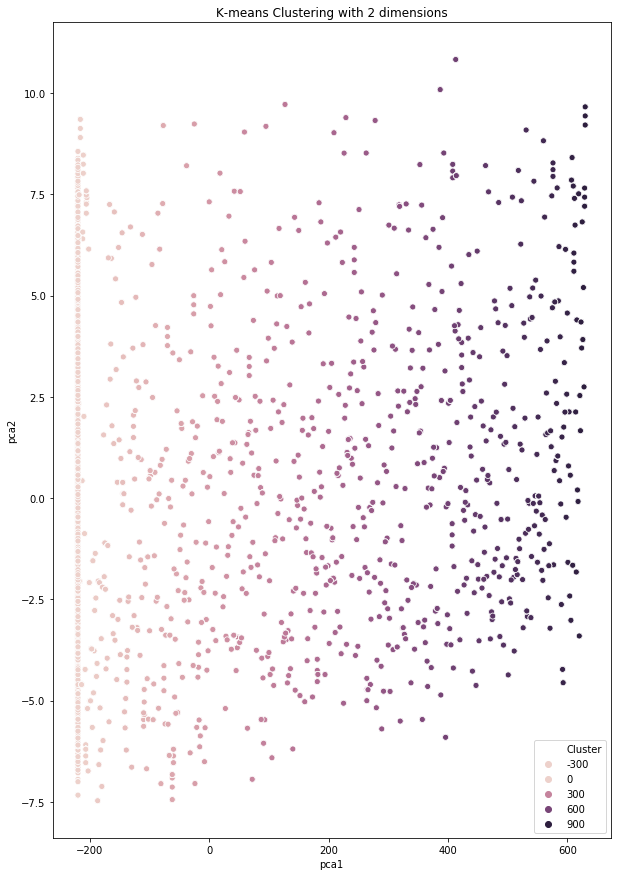

In [368]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
### Run PCA on the data and reduce the dimensions in pca_num_components dimensions
plt.figure(figsize=(10,15))
reduced_data = PCA(n_components=2).fit_transform(df_cluster2)
results = pd.DataFrame(reduced_data,columns=['pca1','pca2'])

sns.scatterplot(x="pca1", y="pca2", hue=df_cluster2['Cluster'], data=results)
plt.title('K-means Clustering with 2 dimensions')
plt.show()

In [166]:
df_cluster2.head()

,is3,is3vs6,isBigger6,Cluster
0,1,1,9,1
1,4,0,2,1
2,6,0,1,1
3,61,3,12,0
4,66,0,3,0


In [178]:
df_mergedatalabel = df_mergedata[df_mergedata['label'] == 1]

In [179]:
df_mergedatalabel.head()

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster,CustID,label
5,147233,2.0,3.0,3.0,8.0,2.0,3.0,3.0,8.0,1,147233.0,1.0
17,889920,18.0,6.0,6.0,6.0,10.0,6.0,6.0,6.0,1,889920.0,1.0
29,993251,4.0,1.0,1.0,20.0,4.0,1.0,1.0,20.0,0,993251.0,1.0
30,995973,1.0,1.0,1.0,5.0,1.0,1.0,1.0,5.0,1,995973.0,1.0
47,1086772,7.0,1.0,1.0,5.0,7.0,1.0,1.0,5.0,1,1086772.0,1.0


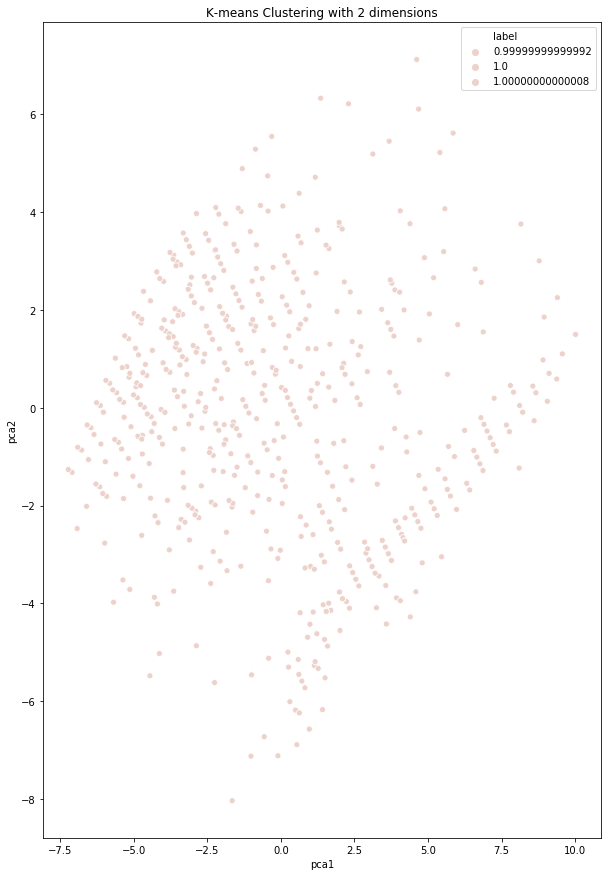

In [320]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
### Run PCA on the data and reduce the dimensions in pca_num_components dimensions
plt.figure(figsize=(10,15))
reduced_data = PCA(n_components=2).fit_transform(df_cluster2)
results = pd.DataFrame(reduced_data,columns=['pca1','pca2'])

sns.scatterplot(x="pca1", y="pca2", hue=df_mergedatalabel['label'], data=results)
plt.title('K-means Clustering with 2 dimensions')
plt.show()

In [148]:
df_cluster['Cluster'].unique()

array([0, 5, 2, 3, 7, 4, 1, 6])

In [280]:
sum_of_squared_distances = []
K = range(1,15)
for k in K:
    k_means = KMeans(n_clusters=k)
    model = k_means.fit(df_cluster[['is1_score', 'is1vs3_score','is3vs6_score', 'isBigger6_score']])
    sum_of_squared_distances.append(k_means.inertia_)

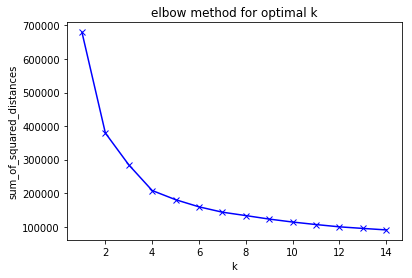

In [281]:
plt.plot(K, sum_of_squared_distances, 'bx-')
plt.xlabel('k')
plt.ylabel('sum_of_squared_distances')
plt.title('elbow method for optimal k')
plt.show()

In [341]:
df_mergedata[(df_mergedata['Cluster'] == 0) & (df_mergedata['label'] == 1)]

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster,CustID,label
9,889920,18.0,6.0,6.0,6.0,10.0,6.0,6.0,6.0,0,889920.0,1.0
24,1285333,9.0,17.0,7.0,18.0,9.0,10.0,7.0,10.0,0,1285333.0,1.0
141,2605810,86.0,46.0,25.0,34.0,10.0,10.0,10.0,10.0,0,2605810.0,1.0
440,7758469,18.0,6.0,9.0,18.0,10.0,6.0,9.0,10.0,0,7758469.0,1.0
451,7938892,25.0,12.0,7.0,10.0,10.0,10.0,7.0,10.0,0,7938892.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
18537,51166315,10.0,11.0,6.0,13.0,10.0,10.0,6.0,10.0,0,51166315.0,1.0
19078,51188544,4.0,20.0,13.0,22.0,4.0,10.0,10.0,10.0,0,51188544.0,1.0
19451,51208726,10.0,7.0,5.0,11.0,10.0,7.0,5.0,10.0,0,51208726.0,1.0
19605,51215481,10.0,16.0,14.0,16.0,10.0,10.0,10.0,10.0,0,51215481.0,1.0


In [342]:
df_mergedata[(df_mergedata['Cluster'] == 0) & (df_mergedata['label'] == 0)]

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster,CustID,label
2,366680,7.0,25.0,20.0,33.0,7.0,10.0,10.0,10.0,0,NaN,0.0
3,401496,16.0,7.0,5.0,5.0,10.0,7.0,5.0,5.0,0,NaN,0.0
5,690171,47.0,26.0,11.0,21.0,10.0,10.0,10.0,10.0,0,NaN,0.0
13,1119565,10.0,21.0,28.0,32.0,10.0,10.0,10.0,10.0,0,NaN,0.0
14,1162525,13.0,9.0,5.0,29.0,10.0,9.0,5.0,10.0,0,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
19616,51215809,7.0,8.0,4.0,13.0,7.0,8.0,4.0,10.0,0,NaN,0.0
19620,51215966,12.0,12.0,13.0,18.0,10.0,10.0,10.0,10.0,0,NaN,0.0
19623,51216332,5.0,6.0,9.0,17.0,5.0,6.0,9.0,10.0,0,NaN,0.0
19636,51217251,18.0,7.0,4.0,13.0,10.0,7.0,4.0,10.0,0,NaN,0.0


In [337]:
df_mergedata[df_mergedata['label'] == 1]

,custid,is1,is1vs3,is3vs6,isBigger6,is1_score,is1vs3_score,is3vs6_score,isBigger6_score,Cluster,CustID,label
1,147233,2.0,3.0,3.0,8.0,2.0,3.0,3.0,8.0,1,147233.0,1.0
9,889920,18.0,6.0,6.0,6.0,10.0,6.0,6.0,6.0,0,889920.0,1.0
18,1234236,14.0,4.0,6.0,8.0,10.0,4.0,6.0,8.0,2,1234236.0,1.0
24,1285333,9.0,17.0,7.0,18.0,9.0,10.0,7.0,10.0,0,1285333.0,1.0
51,1561303,5.5,4.0,1.5,10.5,5.5,4.0,1.5,10.0,2,1561303.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
19483,51210188,4.0,2.0,3.0,14.0,4.0,2.0,3.0,10.0,1,51210188.0,1.0
19484,51210227,2.0,4.0,3.0,14.0,2.0,4.0,3.0,10.0,1,51210227.0,1.0
19605,51215481,10.0,16.0,14.0,16.0,10.0,10.0,10.0,10.0,0,51215481.0,1.0
19622,51216217,2.0,24.0,10.0,13.0,2.0,10.0,10.0,10.0,0,51216217.0,1.0


In [363]:
from sklearn.cluster import DBSCAN
db = DBSCAN()
preds = db.fit_predict(df_cluster[['is1_score', 'is1vs3_score','is3vs6_score', 'isBigger6_score']])

df_cluster['Cluster'] = preds

In [344]:
from sklearn.mixture import GaussianMixture
gm = GaussianMixture(n_components=3, random_state=123, n_init=10)
preds = gm.fit_predict(df_cluster[['is1_score', 'is1vs3_score','is3vs6_score', 'isBigger6_score']])
df_cluster['Cluster'] = preds